# AgriOptima: Post-harvest loss

Predict a published loss percentage from state, crop and stage. The study is aggregated and covers one year; a favourable split is not independent farm-level validation.

Run each cell in order. This notebook trains its own evaluation model and does not overwrite application artifacts.

## 1. Import libraries and find the project
Pandas reads tables; NumPy handles numbers; Matplotlib draws figures.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when Jupyter starts in the project root or this notebook folder.
ROOT = Path.cwd()
if not (ROOT / 'DataSets').exists():
    ROOT = ROOT.parent
assert (ROOT / 'DataSets').exists(), 'Open Jupyter in the project folder.'

## 2. Read, inspect and clean raw data
The source CSVs remain unchanged. Invalid rows and duplicate handling are visible below. Earlier audit records are preserved in the recovery copy outside this project.

In [2]:
raw = pd.read_csv(ROOT / 'DataSets/Food Loss/post_harvest_loss_2022_state_stage.csv')
display(raw.head())
print('Raw rows:', len(raw))
features = ['state', 'crop', 'loss_type', 'stage']
data = raw[features + ['loss_percentage']].copy()
for column in features:
    data[column] = data[column].astype('string').str.strip()
data['loss_percentage'] = pd.to_numeric(data['loss_percentage'], errors='coerce')
valid = data['loss_percentage'].between(0, 100)
for column in features:
    valid = valid & (data[column].str.len().fillna(0) > 0)
data = data.loc[valid].drop_duplicates().reset_index(drop=True)
print('Clean rows:', len(data))

,year,state,crop,loss_type,stage,loss_percentage,source_pdf_page,source_table,source_row
0,2022,Andhra Pradesh,Bajra,Farm Operations,Harvesting,1.17,267,1,6
1,2022,Andhra Pradesh,Bajra,Farm Operations,Collection,0.41,267,1,6
2,2022,Andhra Pradesh,Bajra,Farm Operations,Threshing,1.69,267,1,6
3,2022,Andhra Pradesh,Bajra,Farm Operations,Winnowing/Cleaning,0.15,267,1,6
4,2022,Andhra Pradesh,Bajra,Farm Operations,Drying,0.21,267,1,6


Raw rows: 1865
Clean rows: 1865


### Look at the data
This overview describes the dataset. It is not a prediction result.

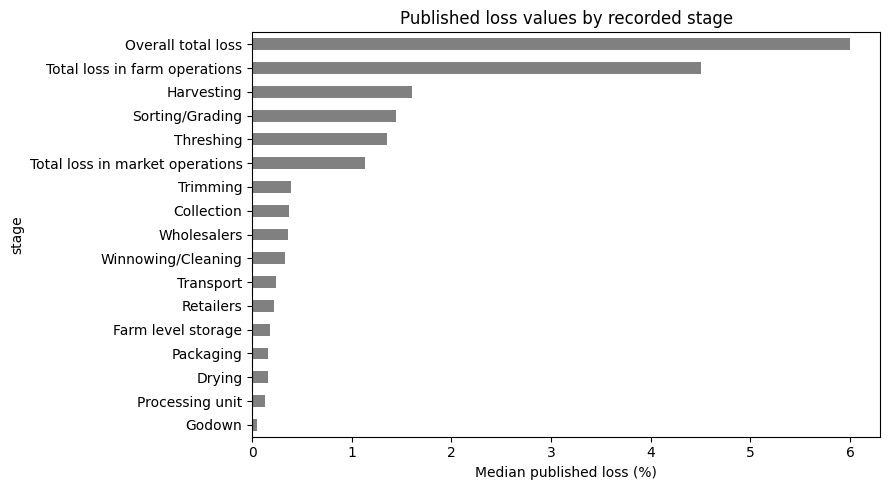

In [3]:
data.groupby('stage')['loss_percentage'].median().sort_values().plot.barh(figsize=(9, 5), color='gray')
plt.xlabel('Median published loss (%)')
plt.title('Published loss values by recorded stage')
plt.tight_layout()
plt.show()

Each bar is the middle published value for that stage across available records. Overall totals and individual stages are different types of records: do not add the bars or treat them as a causal comparison.

## 3. Prepare inputs, split data, train and evaluate
X contains measurements; y contains known answers in supervised tasks. Fit preprocessing on training rows only. Keep time order for prices/yield and keep soil locations together.

In [4]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [5]:
features = ["state", "crop", "loss_type", "stage"]

In [6]:
# 2. Keep every stage of a state/crop combination together in the same split.
groups = data["state"] + "|" + data["crop"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_indices, test_indices = next(splitter.split(data, groups=groups))
train = data.iloc[train_indices]
test = data.iloc[test_indices]

In [7]:
# 3. Turn text categories into numbers and train the forest.
text_steps = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preparation = ColumnTransformer([("categories", text_steps, features)])
forest = RandomForestRegressor(
    n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=1
)
model = Pipeline([("preprocessor", preparation), ("model", forest)])
model.fit(train[features], train["loss_percentage"])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categories',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['state', 'crop', 'loss_type',
                                                   'stage'])])),
                ('model',
                 RandomForestRegressor(min_samples_leaf=2, n_estimators=200,
                                       n_jobs=1, random_state=42))])

In [8]:
# 4. Compare with a constant prediction equal to the training median loss.
predictions = model.predict(test[features])
actual = test["loss_percentage"]
baseline = [train["loss_percentage"].median()] * len(test)
print("Model MAE (percentage points):", mean_absolute_error(actual, predictions))
print("Baseline MAE:", mean_absolute_error(actual, baseline))
print("RMSE:", mean_squared_error(actual, predictions) ** 0.5)
# Only one study year is represented. This split alone is not external validation.

Model MAE (percentage points): 0.36117350754015126
Baseline MAE: 0.9937020408163265
RMSE: 0.6096815819585497


## 4. Figures and interpretation
These figures use held-out predictions when labels exist. For soil, they describe the held-out groups or scores.

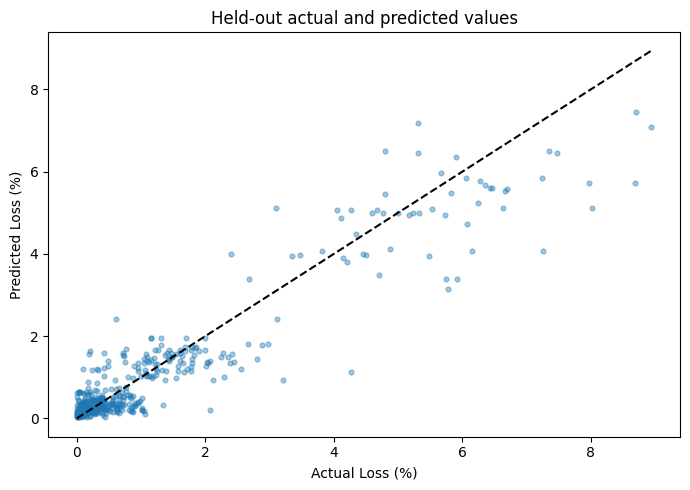

,actual,prediction
0,0.74,1.516837
1,0.39,0.408949
2,2.67,1.817372
3,0.56,0.162158
4,0.62,0.165972


In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(actual, predictions, alpha=0.4, s=12)
low, high = min(actual.min(), predictions.min()), max(actual.max(), predictions.max())
plt.plot([low, high], [low, high], 'k--')
plt.xlabel('Actual Loss (%)')
plt.ylabel('Predicted Loss (%)')
plt.title('Held-out actual and predicted values')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'actual': np.asarray(actual)[:5], 'prediction': predictions[:5]}))

The dashed line is a perfect prediction. Points away from it are errors. MAE gives their average absolute size; the table shows five held-out examples.

## 5. Save this learning model separately
The working application models remain unchanged. The saved bundle includes the features and preprocessing needed for later use. This is the holdout experiment model, not an all-data production refit.

In [10]:
import joblib
output = ROOT / 'saved_models'
output.mkdir(exist_ok=True)
bundle = {'model': model, 'features': features}
joblib.dump(bundle, output / '04_post_harvest_loss.joblib')
print('Learning artifact saved separately.')

Learning artifact saved separately.


## 6. Viva summary and limitations
Predict a published loss percentage from state, crop and stage. The study is aggregated and covers one year; a favourable split is not independent farm-level validation.

Explain: source and target, cleaning choices, split, preprocessing, algorithm, metric, baseline (if applicable), and one limitation. Fitted preprocessing must also be used for new requests. No custom Python functions or classes are defined in this notebook.